# Optical properties of marine particles with a dense core

Companion of `sensitivity_multilayer_particles.ipynb`, where the high-index material was an outer
chloroplast-like shell. Here the high-index material is an **inner core**, which stands for the nucleus
(DNA- and protein-rich) or other dense organelles of phytoplankton cells (pyrenoids, starch grains,
polyphosphate or lipid bodies, crystalline inclusions), surrounded by a low-index cytoplasm. The efficiency
factors, asymmetry parameter, backscattering ratio and scattering matrix are computed with exact multilayer
Mie theory ([scattnlay](https://github.com/ovidiopr/scattnlay); Peña and Pal, 2009).

**Particle models** (refractive indices relative to seawater):

* **two-layer (core–cytoplasm)**: a dense core of real index $m_{core}$ = 1.04 to 1.20 occupying 5, 10 or 25 %
  of the particle volume, in a cytoplasm of index $m_{cyt}$ = 1.02. Indicative values: nucleus 1.04–1.06,
  pyrenoids, starch and protein bodies 1.10–1.15, dense mineral or crystalline inclusions about 1.20,
* **three-layer (core–cytoplasm–chloroplast)**: an organelle core (10 % of the volume), cytoplasm and a
  chloroplast-like outer layer ($m_{chl}$ = 1.10, 25 % of the volume), for a nucleus-like ($m_{core}$ = 1.05)
  or pyrenoid-like ($m_{core}$ = 1.15) core, and without a dense core ($m_{core}$ = $m_{cyt}$, which is the
  two-layer chloroplast model of the companion notebook),
* each layered particle is compared with the **homogeneous sphere of volume-averaged refractive index**
  $\bar{m} = \sum_k v_k m_k$.

**Absorption**: non-absorbing particles, or pigments in the cytoplasm (two-layer, the core does not absorb) or
in the chloroplast layer (three-layer). The volume-averaged imaginary part is the `pigment` spectrum of the
companion notebooks, so the layered particle and its homogeneous equivalent contain the same amount of pigment.

**Assumptions**: concentric layers, the same relative layer radii for all sizes, size distributions of the
outer radius ($r \le$ 40 µm), wavelengths in water ($n_w$ = 1.34) at the OLCI bands.

**Requirements**: `pip install scattnlay` (GPL-3.0). If its import fails with
`GLIBCXX_3.4.32 not found` in an Anaconda environment, update the C++ runtime of the environment
(`conda install -c conda-forge "libstdcxx-ng>=13"`) or start Jupyter with
`LD_PRELOAD=/usr/lib/x86_64-linux-gnu/libstdc++.so.6`. The computations take about 3 minutes on 40 CPUs.

## 1. Setup

In [1]:
import os

# one BLAS thread per process: the scattering computations run in one process per CPU,
# and multithreaded BLAS in each of them oversubscribes the CPUs (and can stall the workers)
for var in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[var] = '1'

import time

import dask
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.patches import Circle
from scattnlay import scattcoeffs, scattnlay

from mopsmap_tbx.opac_mopsmap import ROOT

odir = ROOT / 'scatmat' / 'sensitivity'
odir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.size': 11, 'axes.titlesize': 11, 'axes.labelsize': 11, 'legend.fontsize': 9,
    'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
    'lines.linewidth': 1.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.dpi': 100, 'savefig.dpi': 200,
})
FV_COLORS = ['#86b6ef', '#2a78d6', '#104281']           # core volume fraction (ordinal)
CAT = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']      # categorical
HOMOG = '#5f5e5a'                                       # homogeneous equivalent spheres
print('dask', dask.__version__)

dask 2024.8.0


In [2]:
n_w = 1.34
wl = np.array([400, 412.5, 442.5, 490, 510, 560, 620, 665, 673.75, 681.25,
               708.75, 753.75, 778.75, 865, 885, 900])  # OLCI bands (nm, vacuum)
wl_w = wl * 1e-3 / n_w                                  # wavelength in water (µm)

r_min, r_max = 0.05, 40.                                # outer radius (µm)
r = np.logspace(np.log10(r_min), np.log10(r_max), 1200)
theta = np.concatenate([[0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4], np.arange(0.5, 180.1, 0.5)])
mu = np.cos(np.radians(theta))


def junge(r, xi):
    return r ** -xi


def lognormal(r, r_mod, sigma):
    return np.exp(-0.5 * (np.log(r / r_mod) / np.log(sigma)) ** 2) / r


def gauss(lam, lam0, s):
    return np.exp(-0.5 * ((lam - lam0) / s) ** 2)


psd_def = {
    'J3.0': ('Junge', 'ξ = 3.0', junge(r, 3.0)),
    'J3.5': ('Junge', 'ξ = 3.5', junge(r, 3.5)),
    'J4.0': ('Junge', 'ξ = 4.0', junge(r, 4.0)),
    'J4.5': ('Junge', 'ξ = 4.5', junge(r, 4.5)),
    'LN0.5': ('log-normal', 'r_mod = 0.5 µm', lognormal(r, 0.5, 1.8)),
    'LN1': ('log-normal', 'r_mod = 1 µm', lognormal(r, 1., 1.8)),
    'LN2': ('log-normal', 'r_mod = 2 µm', lognormal(r, 2., 1.8)),
    'LN5': ('log-normal', 'r_mod = 5 µm', lognormal(r, 5., 1.8)),
}
psd_ids = list(psd_def)
dr = np.gradient(r)
n_r = np.array([v[2] / np.sum(v[2] * dr) for v in psd_def.values()])
weights = n_r * dr                                       # (psd, r) quadrature weights

# volume-averaged imaginary part (pigment spectrum of the companion notebooks)
mi_pigment = 2e-4 + 3e-3 * gauss(wl, 442.5, 35) + 1.5e-3 * gauss(wl, 675, 15)

## 2. Particle models

Layers are described by their outer radius relative to the particle radius, from the core to the outer layer.
In the `pigment` case, the imaginary part of the absorbing layer is $\bar{m}_i / v$, with $v$ its volume
fraction, so that the volume-averaged imaginary part is the same for all models.

In [3]:
m_cyt = 1.02
m_cores = [1.04, 1.06, 1.10, 1.15, 1.20]
f_cs = [0.05, 0.10, 0.25]                 # core volume fraction (two-layer)
organelles = {'none': m_cyt, 'nucleus': 1.05, 'pyrenoid': 1.15}
f_core3, m_chl, f_chl = 0.10, 1.10, 0.25
absorptions = ['none', 'pigment']


def two_layer(m_core, f_c, absorption, structure):
    # relative layer radii and refractive indices (wl, layer): dense core in an absorbing cytoplasm
    mi = mi_pigment if absorption == 'pigment' else np.zeros_like(wl)
    if structure == 'homogeneous':
        m_eq = f_c * m_core + (1 - f_c) * m_cyt
        return np.array([1.]), (m_eq + 1j * mi)[:, None]
    frac = np.array([f_c ** (1 / 3), 1.])
    m = np.stack([np.full(len(wl), m_core + 0j), m_cyt + 1j * mi / (1 - f_c)], axis=1)
    return frac, m


def three_layer(organelle, absorption, structure):
    # organelle core / cytoplasm / absorbing chloroplast layer
    mi = mi_pigment if absorption == 'pigment' else np.zeros_like(wl)
    m_core = organelles[organelle]
    if structure == 'homogeneous':
        m_eq = f_core3 * m_core + (1 - f_core3 - f_chl) * m_cyt + f_chl * m_chl
        return np.array([1.]), (m_eq + 1j * mi)[:, None]
    frac = np.array([f_core3 ** (1 / 3), (1 - f_chl) ** (1 / 3), 1.])
    m = np.stack([np.full(len(wl), m_core + 0j), np.full(len(wl), m_cyt + 0j), m_chl + 1j * mi / f_chl], axis=1)
    return frac, m


rows = []
for m_core in m_cores:
    for f_c in f_cs:
        frac, m = two_layer(m_core, f_c, 'pigment', 'layered')
        rows.append(('two-layer', f'm_core = {m_core:.2f}, f_c = {f_c:.2f}', np.round(frac, 3),
                     f_c * m_core + (1 - f_c) * m_cyt, m[5, -1].imag))
for org, mc in organelles.items():
    frac, m = three_layer(org, 'pigment', 'layered')
    m_eq = three_layer(org, 'none', 'homogeneous')[1][0, 0].real
    rows.append(('three-layer', f'{org} core (m = {mc})', np.round(frac, 3), m_eq, m[5, -1].imag))
pd.DataFrame(rows, columns=['model', 'case', 'relative radii', 'volume-averaged m_r',
                            'm_i absorbing layer (560 nm)'])

,model,case,relative radii,volume-averaged m_r,m_i absorbing layer (560 nm)
0,two-layer,"m_core = 1.04, f_c = 0.05","[0.368, 1.0]",1.0210,0.000222
1,two-layer,"m_core = 1.04, f_c = 0.10","[0.464, 1.0]",1.0220,0.000234
2,two-layer,"m_core = 1.04, f_c = 0.25","[0.63, 1.0]",1.0250,0.000281
3,two-layer,"m_core = 1.06, f_c = 0.05","[0.368, 1.0]",1.0220,0.000222
4,two-layer,"m_core = 1.06, f_c = 0.10","[0.464, 1.0]",1.0240,0.000234
5,two-layer,"m_core = 1.06, f_c = 0.25","[0.63, 1.0]",1.0300,0.000281
6,two-layer,"m_core = 1.10, f_c = 0.05","[0.368, 1.0]",1.0240,0.000222
7,two-layer,"m_core = 1.10, f_c = 0.10","[0.464, 1.0]",1.0280,0.000234
8,two-layer,"m_core = 1.10, f_c = 0.25","[0.63, 1.0]",1.0400,0.000281
9,two-layer,"m_core = 1.15, f_c = 0.05","[0.368, 1.0]",1.0265,0.000222


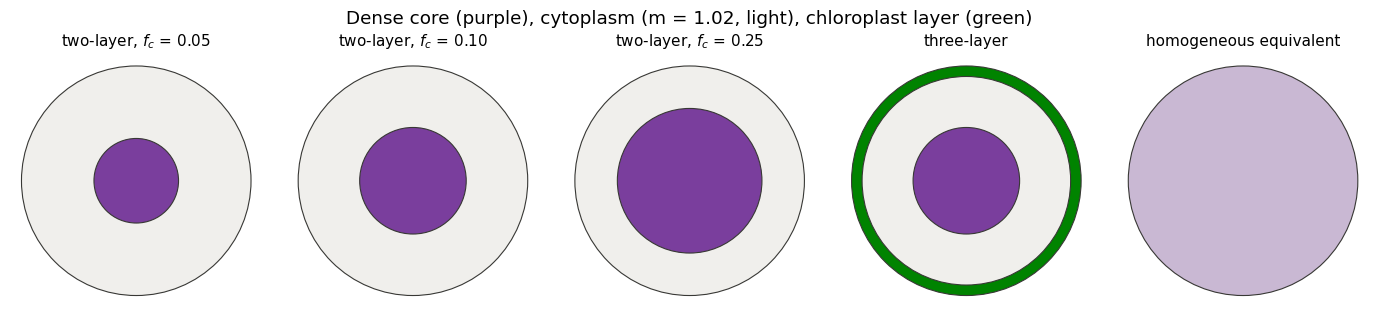

In [4]:
CYT, CORE, CHL = '#f0efec', '#7a3e9d', '#008300'
fig, axs = plt.subplots(1, 5, figsize=(14, 3.2))
models = [('two-layer, $f_c$ = 0.05', two_layer(1.10, 0.05, 'none', 'layered')[0], [CORE, CYT]),
          ('two-layer, $f_c$ = 0.10', two_layer(1.10, 0.10, 'none', 'layered')[0], [CORE, CYT]),
          ('two-layer, $f_c$ = 0.25', two_layer(1.10, 0.25, 'none', 'layered')[0], [CORE, CYT]),
          ('three-layer', three_layer('nucleus', 'none', 'layered')[0], [CORE, CYT, CHL]),
          ('homogeneous equivalent', np.array([1.]), ['#c9b8d3'])]
for ax, (title, frac, colors) in zip(axs, models):
    for f, c in zip(frac[::-1], colors[::-1]):
        ax.add_patch(Circle((0, 0), f, facecolor=c, edgecolor='#383835', lw=0.8))
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(title)
fig.suptitle('Dense core (purple), cytoplasm (m = 1.02, light), chloroplast layer (green)')
plt.tight_layout()

## 3. Multilayer Mie computations

For each particle, `scattcoeffs` gives the multipole coefficients $a_n, b_n$ of the layered sphere and `scattnlay`
the efficiency factors and asymmetry parameter. The amplitude functions are summed as
$S_1 = \sum_n \frac{2n+1}{n(n+1)} (a_n \pi_n + b_n \tau_n)$ and $S_2 = \sum_n \frac{2n+1}{n(n+1)} (a_n \tau_n + b_n \pi_n)$,
with the angular functions $\pi_n(\cos\theta)$, $\tau_n(\cos\theta)$ tabulated once for all scattering angles.
The scattering matrix elements are normalized as in MOPSMAP: $a_1 = a_2 = 4\langle S_{11}\rangle / \langle x^2 Q_{sca}\rangle$,
$a_3 = a_4 \propto \langle S_{33}\rangle$, $b_1 \propto \langle S_{12}\rangle$, $b_2 \propto -\langle S_{34}\rangle$
(Bohren and Huffman, 1983, with $\int S_{11} d\Omega = \pi x^2 Q_{sca}$). See the companion notebook for details.

In [5]:
NMAX = 1200   # larger than the number of terms needed for x = 842 (1025)


def angular_functions(mu, nmax=NMAX):
    # pi_n and tau_n (n = 0..nmax) at the cosines mu
    pi = np.zeros((nmax + 1, len(mu)))
    tau = np.zeros_like(pi)
    pi[1] = 1.
    for n in range(2, nmax + 1):
        pi[n] = ((2 * n - 1) * mu * pi[n - 1] - n * pi[n - 2]) / (n - 1)
    n = np.arange(1, nmax + 1)[:, None]
    tau[1:] = n * mu * pi[1:] - (n + 1) * pi[:-1]
    return pi, tau


def amplitudes(x_layers, m_layers, pi, tau):
    # S1, S2 of a layered sphere from its multipole coefficients
    terms, an, bn = scattcoeffs(x_layers, m_layers)
    n = np.arange(1, len(an) + 1)
    f = (2 * n + 1) / (n * (n + 1))
    A, B = f * an, f * bn
    P, T = pi[1:len(an) + 1], tau[1:len(an) + 1]
    return A @ P + B @ T, A @ T + B @ P


# check against scattnlay's own amplitude functions for dense-core particles
pi, tau = angular_functions(mu)
for x, frac, m in [(100., [0.46, 1.], [1.20, 1.02 + 0.002j]), (300., [0.46, 0.91, 1.], [1.15, 1.02, 1.10 + 0.01j]),
                   (842., [0.37, 1.], [1.10, 1.02 + 0.003j])]:
    X, M = x * np.array(frac), np.array(m, complex)
    S1, S2 = amplitudes(X, M, pi, tau)
    ref = scattnlay(X, M, np.radians(theta))
    err = np.max(np.abs((np.abs(S1) ** 2 + np.abs(S2) ** 2) / (np.abs(ref[8]) ** 2 + np.abs(ref[9]) ** 2) - 1))
    print(f'x = {x:5.0f}, {len(m)} layer(s): max relative difference of S11 = {err:.1e}')

x =   100, 2 layer(s): max relative difference of S11 = 1.8e-14


x =   300, 3 layer(s): max relative difference of S11 = 1.4e-14


x =   842, 2 layer(s): max relative difference of S11 = 1.1e-13


In [6]:
@dask.delayed
def multilayer_case(frac, m_layers, wl_w, r, mu, weights):
    # size-averaged Qext, ssa, g (psd,) and scattering matrix (psd, theta, element) at one wavelength
    import numpy as np
    from scattnlay import scattnlay

    pi, tau = angular_functions(mu)
    k = 2 * np.pi / wl_w
    qext, qsca, g = (np.empty(len(r)) for _ in range(3))
    S11, S12, S33, S34 = (np.empty((len(r), len(mu))) for _ in range(4))
    for i, ri in enumerate(r):
        X = np.asarray(frac) * k * ri
        out = scattnlay(X, m_layers)
        qext[i], qsca[i], g[i] = out[1], out[2], out[6]
        S1, S2 = amplitudes(X, m_layers, pi, tau)
        S11[i] = (np.abs(S2) ** 2 + np.abs(S1) ** 2) / 2
        S12[i] = (np.abs(S2) ** 2 - np.abs(S1) ** 2) / 2
        S33[i] = np.real(S2 * np.conj(S1))
        S34[i] = np.imag(S2 * np.conj(S1))
    x = k * r
    G = np.pi * r ** 2
    Qext = weights @ (G * qext) / (weights @ G)
    Qsca = weights @ (G * qsca) / (weights @ G)
    gg = weights @ (G * qsca * g) / (weights @ (G * qsca))
    den = (weights @ (x ** 2 * qsca))[:, None] / 4
    a1, a3 = weights @ S11 / den, weights @ S33 / den
    b1, b2 = weights @ S12 / den, -(weights @ S34) / den
    return Qext, Qsca / Qext, gg, np.stack([a1, a1, a3, a3, b1, b2], axis=-1).astype('float32')


structures = ['layered', 'homogeneous']
keys2 = [(s, a, mc, fc) for s in structures for a in absorptions for mc in m_cores for fc in f_cs]
keys3 = [(s, a, o) for s in structures for a in absorptions for o in organelles]
tasks = []
for key in keys2:
    frac, m = two_layer(key[2], key[3], key[1], key[0])
    tasks += [multilayer_case(frac, m[iw], wl_w[iw], r, mu, weights) for iw in range(len(wl))]
for key in keys3:
    frac, m = three_layer(key[2], key[1], key[0])
    tasks += [multilayer_case(frac, m[iw], wl_w[iw], r, mu, weights) for iw in range(len(wl))]
print(len(keys2) + len(keys3), 'particle models,', len(tasks), 'tasks')
t0 = time.perf_counter()
res = dask.compute(*tasks, scheduler='processes', num_workers=os.cpu_count())
print(f'done in {time.perf_counter() - t0:.0f} s')

72 particle models, 1152 tasks


done in 159 s


### Gathering the results

In [7]:
elements = ['a1', 'a2', 'a3', 'a4', 'b1', 'b2']


def gather(res, shape, dims, coords):
    # results ordered as (cases..., wl) with arrays over psd -> Dataset (cases..., wl, psd)
    out = [np.array([x[i] for x in res]) for i in range(4)]
    out = [o.reshape(shape + (len(wl),) + o.shape[1:]) for o in out]
    d = dims + ('wl', 'psd')
    ds = xr.Dataset({'Qext': (d, out[0]), 'ssa': (d, out[1]), 'g': (d, out[2]),
                     'F': (d + ('theta', 'element'), out[3])},
                    coords=dict(coords, wl=wl, psd=psd_ids, theta=theta, element=elements))
    ds = ds.assign_coords(theta_rad=('theta', np.radians(theta)))
    a1 = ds.F.sel(element='a1')
    a1s = a1 * np.sin(ds.theta_rad)
    ds['bb_ratio'] = a1s.where(ds.theta >= 90, drop=True).integrate('theta_rad') / a1s.integrate('theta_rad')
    ds['Qsca'] = ds.Qext * ds.ssa
    ds['Qabs'] = ds.Qext - ds.Qsca
    ds['Qbb'] = ds.Qsca * ds.bb_ratio
    ds['dolp'] = -ds.F.sel(element='b1') / a1
    return ds


n2 = len(keys2) * len(wl)
ds2 = gather(res[:n2], (len(structures), len(absorptions), len(m_cores), len(f_cs)),
             ('structure', 'absorption', 'm_core', 'f_c'),
             dict(structure=structures, absorption=absorptions, m_core=m_cores, f_c=f_cs))
ds2 = ds2.assign_coords(m_eq=(('m_core', 'f_c'), np.outer(m_cores, f_cs) + (1 - np.array(f_cs)) * m_cyt))
ds3 = gather(res[n2:], (len(structures), len(absorptions), len(organelles)), ('structure', 'absorption', 'organelle'),
             dict(structure=structures, absorption=absorptions, organelle=list(organelles)))
ds2

<xarray.Dataset> Size: 80MB
Dimensions:     (structure: 2, absorption: 2, m_core: 5, f_c: 3, wl: 16,
                 psd: 8, theta: 369, element: 6)
Coordinates:
  * structure   (structure) <U11 88B 'layered' 'homogeneous'
  * absorption  (absorption) <U7 56B 'none' 'pigment'
  * m_core      (m_core) float64 40B 1.04 1.06 1.1 1.15 1.2
  * f_c         (f_c) float64 24B 0.05 0.1 0.25
  * wl          (wl) float64 128B 400.0 412.5 442.5 490.0 ... 865.0 885.0 900.0
  * psd         (psd) <U5 160B 'J3.0' 'J3.5' 'J4.0' 'J4.5' ... 'LN1' 'LN2' 'LN5'
  * theta       (theta) float64 3kB 0.0 0.001 0.005 0.01 ... 179.0 179.5 180.0
  * element     (element) <U2 48B 'a1' 'a2' 'a3' 'a4' 'b1' 'b2'
    theta_rad   (theta) float64 3kB 0.0 1.745e-05 8.727e-05 ... 3.133 3.142
    m_eq        (m_core, f_c) float64 120B 1.021 1.022 1.025 ... 1.038 1.065
Data variables:
    Qext        (structure, absorption, m_core, f_c, wl, psd) float64 61kB 1....
    ssa         (structure, absorption, m_core, f_c, wl, psd) float64 61kB 1....
    g           (structure, absorption, m_core, f_c, wl, psd) float64 61kB 0....
    F           (structure, absorption, m_core, f_c, wl, psd, theta, element) float32 68MB ...
    bb_ratio    (structure, absorption, m_core, f_c, wl, psd) float64 61kB 0....
    Qsca        (structure, absorption, m_core, f_c, wl, psd) float64 61kB 1....
    Qabs        (structure, absorption, m_core, f_c, wl, psd) float64 61kB -1...
    Qbb         (structure, absorption, m_core, f_c, wl, psd) float64 61kB 0....
    dolp        (structure, absorption, m_core, f_c, wl, psd, theta) float32 11MB ...

## 4. Dense-core vs homogeneous particles

### Two-layer particles as a function of the volume-averaged refractive index

Non-absorbing particles at 560 nm. Homogeneous spheres (gray) and dense-core particles (colored by core volume
fraction, one point per $m_{core}$ = 1.04, 1.06, 1.10, 1.15, 1.20) are plotted against the same volume-averaged
refractive index $\bar{m}_r$.

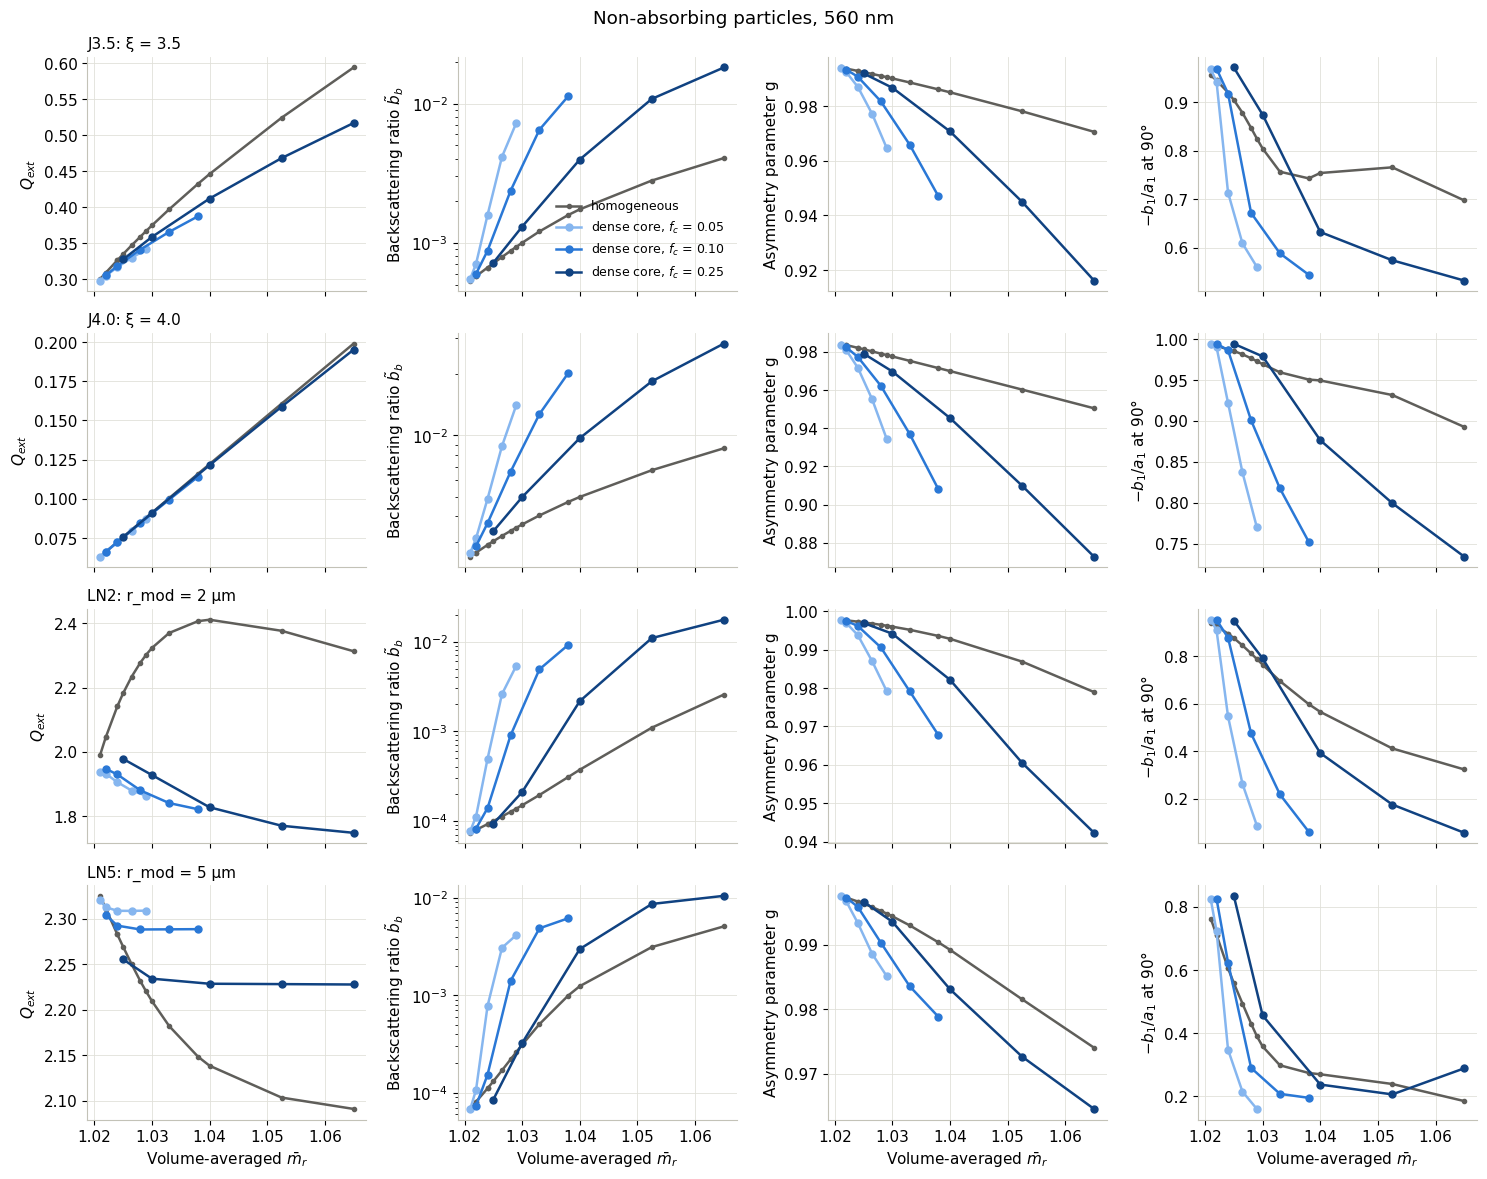

In [8]:
panels = [('Qext', '$Q_{ext}$'), ('bb_ratio', 'Backscattering ratio $\\tilde{b}_b$'), ('g', 'Asymmetry parameter g'),
          ('dolp90', '$-b_1/a_1$ at 90°')]
sub = ds2.sel(absorption='none', wl=560)
sub['dolp90'] = sub.dolp.sel(theta=90)
psds = ['J3.5', 'J4.0', 'LN2', 'LN5']
fig, axs = plt.subplots(len(psds), 4, figsize=(15, 3 * len(psds)), sharex=True)
for i, p in enumerate(psds):
    for j, (v, label) in enumerate(panels):
        ax = axs[i, j]
        h = sub[v].sel(structure='homogeneous', psd=p)
        order = np.argsort(sub.m_eq.values.ravel())
        ax.plot(sub.m_eq.values.ravel()[order], h.values.ravel()[order], 'o-', ms=3, color=HOMOG, label='homogeneous')
        for fc, c in zip(f_cs, FV_COLORS):
            lay = sub[v].sel(structure='layered', psd=p, f_c=fc)
            ax.plot(sub.m_eq.sel(f_c=fc), lay, 'o-', ms=5, color=c, label=f'dense core, $f_c$ = {fc:.2f}')
        if v == 'bb_ratio':
            ax.set_yscale('log')
        ax.set_ylabel(label)
    axs[i, 0].set_title(f'{p}: {psd_def[p][1]}', loc='left')
for ax in axs[-1]:
    ax.set_xlabel('Volume-averaged $\\bar{m}_r$')
axs[0, 1].legend(frameon=False)
fig.suptitle('Non-absorbing particles, 560 nm')
plt.tight_layout()

### Ratio of dense-core to homogeneous particles

Range over the eight size distributions at 560 nm (non-absorbing).

In [9]:
sub = ds2.sel(absorption='none', wl=560)
rows = {}
for v in ['Qext', 'bb_ratio', 'g']:
    ratio = sub[v].sel(structure='layered') / sub[v].sel(structure='homogeneous')
    for fc in f_cs:
        rows[(v, f'f_c = {fc:.2f}')] = [f'{float(ratio.sel(m_core=mc, f_c=fc).min()):.2f}–'
                                        f'{float(ratio.sel(m_core=mc, f_c=fc).max()):.2f}' for mc in m_cores]
table = pd.DataFrame(rows, index=[f'm_core = {mc:.2f}' for mc in m_cores]).T
table

m_core = 1.04 m_core = 1.06 m_core = 1.10 m_core = 1.15  \
Qext     f_c = 0.05     0.97–1.02     0.94–1.03     0.89–1.06     0.82–1.09   
         f_c = 0.10     0.95–1.03     0.90–1.05     0.83–1.09     0.71–1.14   
         f_c = 0.25     0.91–1.05     0.83–1.07     0.73–1.12     0.61–1.16   
bb_ratio f_c = 0.05     0.98–1.05     1.13–1.41     1.39–7.04    1.84–23.26   
         f_c = 0.10     0.91–1.08     1.21–1.51     1.57–7.15    2.07–25.33   
         f_c = 0.25     0.65–1.12     1.04–1.41     1.60–5.83    1.94–14.13   
g        f_c = 0.05     1.00–1.00     0.99–1.00     0.98–1.00     0.96–0.99   
         f_c = 0.10     1.00–1.00     0.99–1.00     0.97–1.00     0.94–0.99   
         f_c = 0.25     0.99–1.00     0.98–1.00     0.96–0.99     0.93–0.99   

                    m_core = 1.20  
Qext     f_c = 0.05     0.74–1.13  
         f_c = 0.10     0.62–1.17  
         f_c = 0.25     0.55–1.17  
bb_ratio f_c = 0.05    2.35–39.55  
         f_c = 0.10    2.55–37.10  
         f_c = 0.25    2.06–15.85  
g        f_c = 0.05     0.93–0.99  
         f_c = 0.10     0.90–0.99  
         f_c = 0.25     0.89–0.99

### Backscattering spectra

Backscattering efficiency $Q_{bb}$ of non-absorbing particles with $f_c$ = 0.10 (solid) and of their homogeneous
equivalents (dashed).

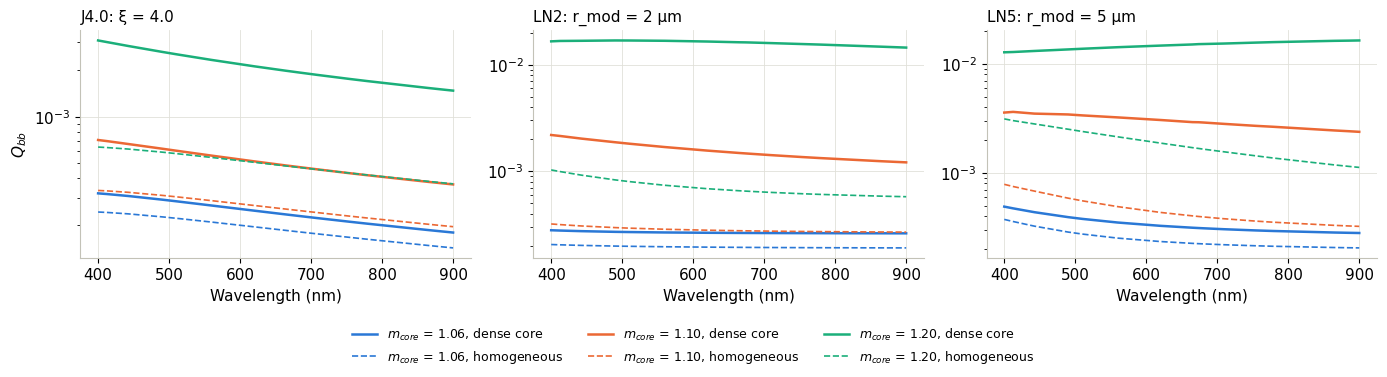

In [10]:
psds = ['J4.0', 'LN2', 'LN5']
colors = dict(zip([1.06, 1.10, 1.20], CAT))
fig, axs = plt.subplots(1, len(psds), figsize=(14, 3.8), sharex=True)
for ax, p in zip(axs, psds):
    for mc, c in colors.items():
        d = ds2.sel(absorption='none', psd=p, f_c=0.10, m_core=mc)
        ax.plot(wl, d.Qbb.sel(structure='layered'), color=c, label=f'$m_{{core}}$ = {mc:.2f}, dense core')
        ax.plot(wl, d.Qbb.sel(structure='homogeneous'), '--', color=c, lw=1.2, label=f'$m_{{core}}$ = {mc:.2f}, homogeneous')
    ax.set_yscale('log')
    ax.set_title(f'{p}: {psd_def[p][1]}', loc='left')
    ax.set_xlabel('Wavelength (nm)')
axs[0].set_ylabel('$Q_{bb}$')
fig.legend(*axs[0].get_legend_handles_labels(), loc='lower center', ncol=3, frameon=False, fontsize=9)
plt.tight_layout(rect=(0, 0.14, 1, 1))

### Scattering matrix

Dense-core particles with $f_c$ = 0.10 (solid) and their homogeneous equivalents (dashed), non-absorbing, 560 nm.

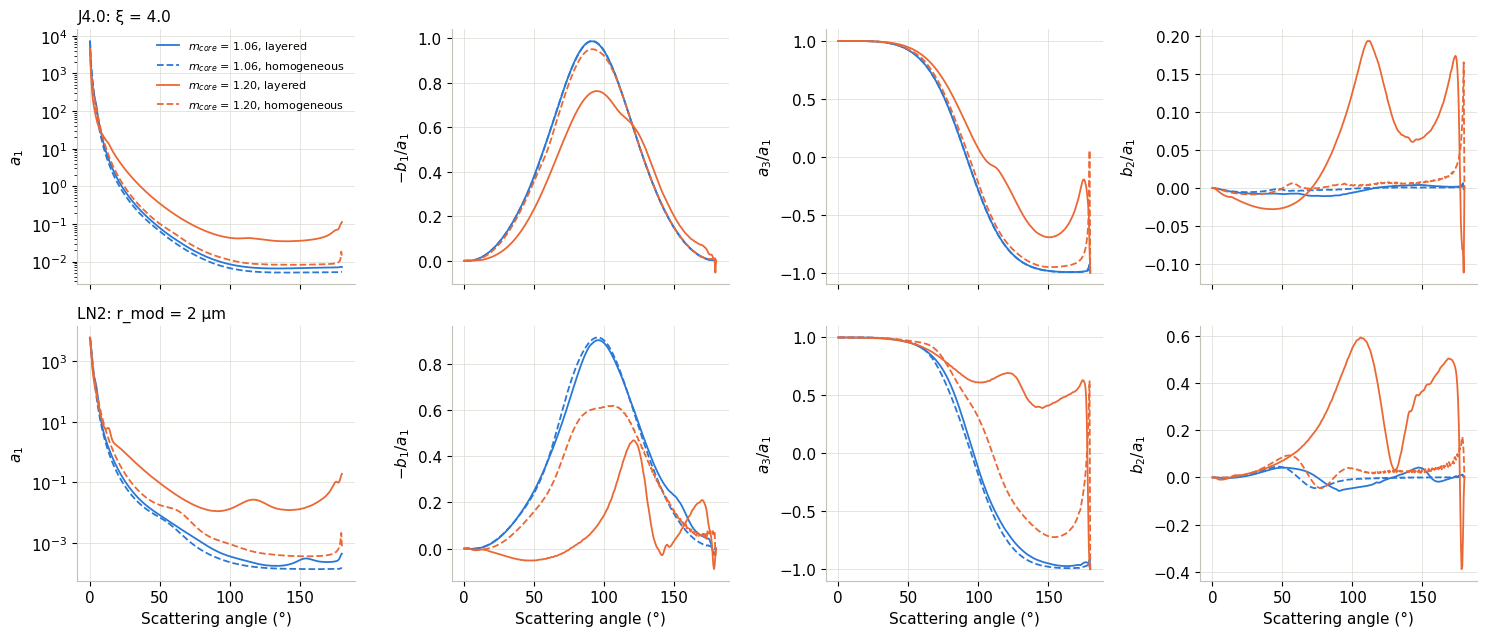

In [11]:
panels = [('a1', '$a_1$'), ('dolp', '$-b_1/a_1$'), ('a3', '$a_3/a_1$'), ('b2', '$b_2/a_1$')]
fig, axs = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
for i, p in enumerate(['J4.0', 'LN2']):
    s = ds2.sel(absorption='none', wl=560, psd=p, f_c=0.10)
    for mc, c in zip([1.06, 1.20], CAT):
        for st, ls in [('layered', '-'), ('homogeneous', '--')]:
            d = s.sel(m_core=mc, structure=st)
            a1 = d.F.sel(element='a1')
            lab = f'$m_{{core}}$ = {mc:.2f}, {st}'
            for j, (v, label) in enumerate(panels):
                y = a1 if v == 'a1' else d.dolp if v == 'dolp' else d.F.sel(element=v) / a1
                axs[i, j].plot(d.theta, y, ls=ls, color=c, lw=1.3, label=lab)
                axs[i, j].set_ylabel(label)
    axs[i, 0].set_yscale('log')
    axs[i, 0].set_title(f'{p}: {psd_def[p][1]}', loc='left')
for ax in axs[1]:
    ax.set_xlabel('Scattering angle (°)')
axs[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()

### Absorption: pigments in the cytoplasm

$Q_{abs}$ of dense-core particles relative to their homogeneous equivalents (same amount of pigment, excluded from
the core), and single scattering albedo, for $m_{core}$ = 1.10.

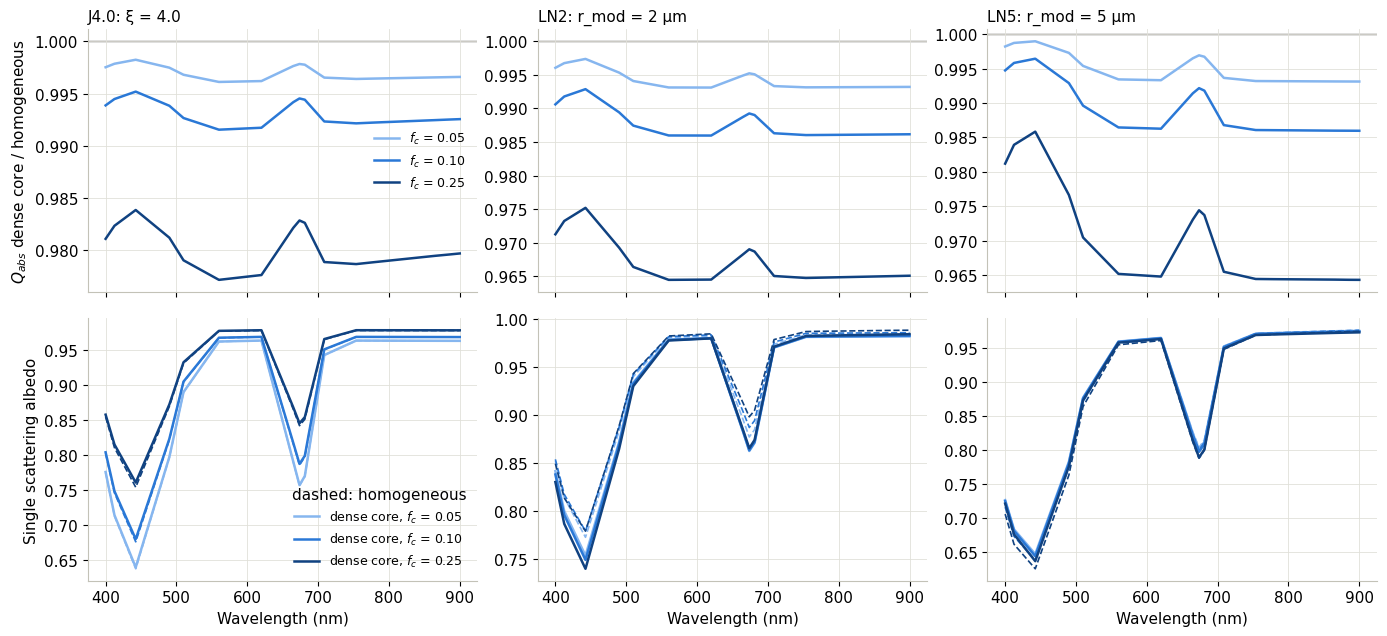

In [12]:
psds = ['J4.0', 'LN2', 'LN5']
fig, axs = plt.subplots(2, len(psds), figsize=(14, 6.5), sharex=True)
for j, p in enumerate(psds):
    s = ds2.sel(absorption='pigment', psd=p, m_core=1.10)
    for fc, c in zip(f_cs, FV_COLORS):
        d = s.sel(f_c=fc)
        axs[0, j].plot(wl, d.Qabs.sel(structure='layered') / d.Qabs.sel(structure='homogeneous'), color=c,
                       label=f'$f_c$ = {fc:.2f}')
        axs[1, j].plot(wl, d.ssa.sel(structure='layered'), color=c, label=f'dense core, $f_c$ = {fc:.2f}')
        axs[1, j].plot(wl, d.ssa.sel(structure='homogeneous'), '--', color=c, lw=1.2)
    axs[0, j].axhline(1, color=HOMOG, lw=1, zorder=-1)
    axs[0, j].set_title(f'{p}: {psd_def[p][1]}', loc='left')
    axs[1, j].set_xlabel('Wavelength (nm)')
axs[0, 0].set_ylabel('$Q_{abs}$ dense core / homogeneous')
axs[1, 0].set_ylabel('Single scattering albedo')
axs[0, 0].legend(frameon=False)
axs[1, 0].legend(frameon=False, title='dashed: homogeneous')
plt.tight_layout()

### Three-layer cells: organelle core, cytoplasm and chloroplast layer

Cells with a chloroplast layer ($m_{chl}$ = 1.10, 25 % of the volume, with pigments) and a nucleus-like or
pyrenoid-like core (10 % of the volume), compared with the same cell without a dense core
(solid: layered, dashed: homogeneous equivalent).

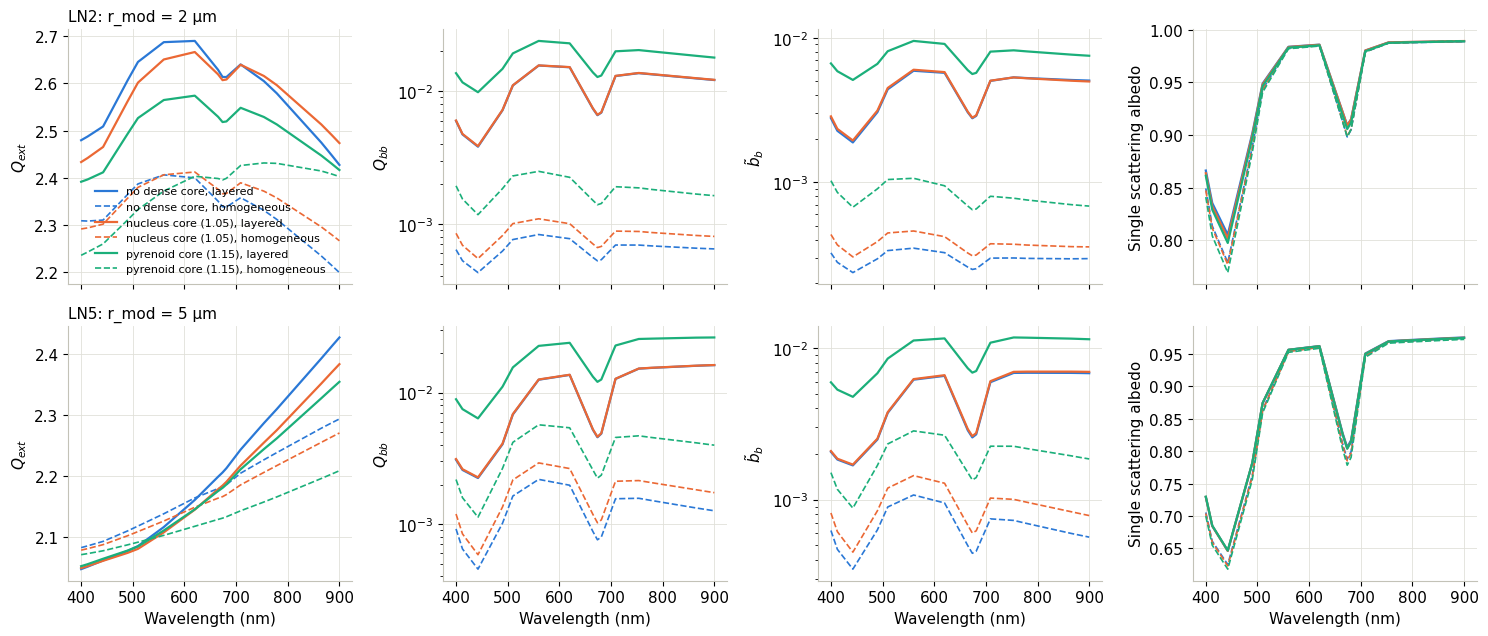

In [13]:
panels = [('Qext', '$Q_{ext}$'), ('Qbb', '$Q_{bb}$'), ('bb_ratio', '$\\tilde{b}_b$'), ('ssa', 'Single scattering albedo')]
labels = {'none': 'no dense core', 'nucleus': 'nucleus core (1.05)', 'pyrenoid': 'pyrenoid core (1.15)'}
fig, axs = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
for i, p in enumerate(['LN2', 'LN5']):
    for org, c in zip(organelles, CAT):
        d = ds3.sel(absorption='pigment', psd=p, organelle=org)
        for st, ls in [('layered', '-'), ('homogeneous', '--')]:
            for j, (v, label) in enumerate(panels):
                axs[i, j].plot(wl, d[v].sel(structure=st), ls=ls, color=c, lw=1.6 if ls == '-' else 1.2,
                               label=f'{labels[org]}, {st}')
                axs[i, j].set_ylabel(label)
    axs[i, 1].set_yscale('log')
    axs[i, 2].set_yscale('log')
    axs[i, 0].set_title(f'{p}: {psd_def[p][1]}', loc='left')
for ax in axs[1]:
    ax.set_xlabel('Wavelength (nm)')
axs[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()

In [14]:
sub = ds3.sel(absorption='none', wl=560)
rows = {}
for v in ['Qext', 'bb_ratio', 'g']:
    for org in ['nucleus', 'pyrenoid']:
        lay = sub[v].sel(organelle=org, structure='layered')
        rows[(v, f'{org} / no dense core')] = (lay / sub[v].sel(organelle='none', structure='layered')).to_pandas()
        rows[(v, f'{org} / homogeneous')] = (lay / sub[v].sel(organelle=org, structure='homogeneous')).to_pandas()
pd.DataFrame(rows).T.round(2)

psd                                J3.0  J3.5  J4.0  J4.5  LN0.5    LN1  \
Qext     nucleus / no dense core   1.02  1.04  1.08  1.12   1.11   1.04   
         nucleus / homogeneous     1.03  1.02  1.00  0.96   0.99   1.07   
         pyrenoid / no dense core  1.05  1.15  1.32  1.57   1.35   1.04   
         pyrenoid / homogeneous    1.01  1.00  0.99  1.00   0.93   0.97   
bb_ratio nucleus / no dense core   0.99  0.98  0.98  0.99   0.91   0.97   
         nucleus / homogeneous     4.68  4.08  2.08  1.24   9.38  13.85   
         pyrenoid / no dense core  1.46  1.36  1.33  1.32   1.03   1.36   
         pyrenoid / homogeneous    4.55  3.95  2.25  1.45   8.01  11.27   
g        nucleus / no dense core   1.00  1.00  1.00  1.00   1.00   1.00   
         nucleus / homogeneous     0.98  0.98  0.98  0.99   0.98   0.98   
         pyrenoid / no dense core  0.99  0.98  0.98  0.97   0.99   0.99   
         pyrenoid / homogeneous    0.97  0.97  0.97  0.97   0.97   0.97   

psd                                  LN2   LN5  
Qext     nucleus / no dense core    0.99  1.00  
         nucleus / homogeneous      1.10  0.99  
         pyrenoid / no dense core   0.95  1.00  
         pyrenoid / homogeneous     1.08  1.00  
bb_ratio nucleus / no dense core    1.02  1.01  
         nucleus / homogeneous     14.96  5.47  
         pyrenoid / no dense core   1.51  1.56  
         pyrenoid / homogeneous     9.58  4.37  
g        nucleus / no dense core    1.00  1.00  
         nucleus / homogeneous      0.98  0.98  
         pyrenoid / no dense core   0.99  0.98  
         pyrenoid / homogeneous     0.97  0.97

## Main results

Dense-core particles are compared with homogeneous spheres of the same size and the same volume-averaged
refractive index $\bar{m}_r$ (all OLCI bands and the eight size distributions):

* **A dense core increases backscattering, as soon as it is optically distinct from the cytoplasm.** The
  backscattering ratio $\tilde{b}_b$ of the layered particle, relative to the homogeneous equivalent, is
  ×0.9–1.5 for a nucleus-like core ($m_{core}$ = 1.06), ×1.3–8 for $m_{core}$ = 1.10 and up to ×25–40 for
  $m_{core}$ = 1.15–1.20 with the log-normal distributions; the steep Junge distributions (J4.0, J4.5) show the
  smallest effect (×1.0–4.9). At a given $\bar{m}_r$, the smaller and denser the core, the larger the
  enhancement. For a large weakly refracting core ($m_{core}$ = 1.04, $f_c$ = 0.25), $\tilde{b}_b$ can instead be
  lower than for the homogeneous sphere (down to ×0.5 for LN5 in the blue).
* **$Q_{ext}$ is much more affected than with a dense outer shell.** It decreases down to 0.55–0.6 times the
  homogeneous value for the LN1 and LN2 distributions with $m_{core}$ ≥ 1.15, and ranges from 0.55 to 1.23 overall,
  while the Junge distributions stay within 0.86–1.17 (shift of the interference structure of $Q_{ext}$).
* **The asymmetry parameter decreases** by up to 11 % ($m_{core}$ = 1.20, J4.5), less for smaller $m_{core}$.
* **The polarized elements change strongly** for the densest cores: $-b_1/a_1$ at 90° drops, $a_3/a_1$ no longer
  reaches −1 in the backward hemisphere, and $b_2/a_1$ reaches 0.2 (J4.0) to 0.6 (LN2) where it stays close to 0
  for the homogeneous sphere.
* **Absorption is barely affected** when the pigment is only excluded from the core: $Q_{abs}$ is 0.92–1.01 times
  that of the homogeneous equivalent. The single scattering albedo changes by −0.07 to +0.04 in the blue band,
  mostly because the dense core changes the scattering.
* **In three-layer cells with a chloroplast layer**, a nucleus-like core ($m_{core}$ = 1.05, 10 % of the volume)
  hardly changes $\tilde{b}_b$ (×0.89–1.02) compared with the same cell without a dense core, the chloroplast layer
  dominating. A pyrenoid-like core ($m_{core}$ = 1.15) increases $Q_{bb}$ by a factor 1.4–2.1. Both remain 1.2–15
  times above the backscattering ratio of their homogeneous equivalents.

As for the chloroplast-shell models, these results are for idealized concentric spheres. Real organelles are
off-centered, non-spherical and numerous, which smooths the angular features; the multilayer results indicate
the sensitivity to the internal structure rather than a model of a given species.

## 5. Saving the results

In [15]:
ofile = odir / 'sensitivity_core_particles.nc'
attrs = dict(refractive_index='relative to seawater, n_w = 1.34', wavelength='OLCI bands in vacuum (nm)',
             radius_range_um=f'{r_min}-{r_max}', method='multilayer Mie theory (scattnlay)')
ds2.drop_vars('theta_rad').assign_attrs(attrs, model='two-layer: dense core + cytoplasm m=1.02').to_netcdf(
    ofile, group='two_layer', encoding={'F': {'zlib': True, 'complevel': 4}})
ds3.drop_vars('theta_rad').assign_attrs(attrs, model='three-layer: organelle core, cytoplasm, chloroplast').to_netcdf(
    ofile, group='three_layer', mode='a', encoding={'F': {'zlib': True, 'complevel': 4}})
print(ofile, f'{ofile.stat().st_size / 1e6:.1f} MB')

/home/harmel/Dropbox/Dropbox/work/git/vrtc/mopsmap_tbx/scatmat/sensitivity/sensitivity_core_particles.nc 71.4 MB
